# Vérification et classement automatique des factures (CNN + OCR)
Projet de Deep Learning — 5IIR-DDSI

**Contenu du notebook**

| Partie | Contenu |
|---|---|
| 0 | Configuration (Google Drive) |
| 1 | Données : FATURA, CORD, RVL-CDIP, construction du jeu de type |
| 2 | Classifieur de type (invoice / receipt / other) : entraînement, évaluation |
| 3 | Jeu de données de qualité (dégradations synthétiques) |
| 4 | Classifieur de qualité (good / poor) : entraînement, matrice, ROC |
| 5 | OCR et extraction des champs, évaluation sur FATURA |
| 6 | Courbes d'entraînement (réentraînement des deux modèles) |

**Pour exécuter** : activer le GPU (Exécution → Modifier le type d'exécution), puis lancer les cellules dans l'ordre.
Les cellules de sauvegarde et de restauration sur Drive (1.4, 3.2) ne sont à lancer qu'au besoin.

## 0. Configuration

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

ROOT = "/content/drive/MyDrive"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Données

### 1.1 Téléchargement (FATURA, CORD, RVL-CDIP)

In [ ]:
# FATURA (Zenodo, ~690 Mo)
!wget -q --show-progress -O FATURA2.zip "https://zenodo.org/records/10371464/files/FATURA2.zip?download=1"
!unzip -q FATURA2.zip -d /content/fatura
!ls /content/fatura

FATURA2.zip         100%[===================>] 658.72M  2.75MB/s    in 4m 56s  
invoices_dataset_final


In [ ]:
# CORD (tickets, CC BY 4.0) et RVL-CDIP factures
!pip -q install datasets
from datasets import load_dataset

cord = load_dataset("naver-clova-ix/cord-v1")
print(cord)

inv = load_dataset("chainyo/rvl-cdip-invoice")
print(inv)

In [ ]:
# Échantillon des autres classes RVL-CDIP, sans télécharger les 39 Go
import os
from itertools import islice

N = 500
os.makedirs("/content/rvl_other", exist_ok=True)
stream = load_dataset("chainyo/rvl-cdip", split="train", streaming=True)

for i, ex in enumerate(islice(stream, N)):
    ex["image"].convert("RGB").save(f"/content/rvl_other/{i}_{ex['label']}.png")

README.md:   0%|          | 0.00/1.72k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/119 [00:00<?, ?it/s]

dataset_infos.json:   0%|          | 0.00/1.25k [00:00<?, ?B/s]

### 1.2 Vérification de la structure

In [ ]:
# Vérifier la structure
import glob
jpgs = glob.glob("/content/fatura/**/*.jpg", recursive=True)
print(len(jpgs), jpgs[:3])
!ls /content/rvl_other | head -5

20000 ['/content/fatura/invoices_dataset_final/colored_images/Template19_Instance177.jpg', '/content/fatura/invoices_dataset_final/colored_images/Template47_Instance57.jpg', '/content/fatura/invoices_dataset_final/colored_images/Template8_Instance110.jpg']
0_0.png
100_0.png
10_0.png
101_0.png
102_0.png


### 1.3 Construction du jeu de type (train / val / test)

In [ ]:
# Construire train/val/test (facture / ticket / autre)
import os, random, shutil
from datasets import load_dataset
random.seed(42)

def split_save(items, cls, save_fn, n):
    items = random.sample(items, min(n, len(items)))
    for i, it in enumerate(items):
        s = "train" if i < 0.7*len(items) else "val" if i < 0.85*len(items) else "test"
        d = f"/content/data/{s}/{cls}"; os.makedirs(d, exist_ok=True)
        save_fn(it, f"{d}/{cls}_{i}.png")

# factures : 1000 images FATURA
split_save(jpgs, "invoice",
           lambda p, out: __import__("PIL.Image").Image.open(p).convert("RGB").save(out), 1000)

# tickets : CORD
cord = load_dataset("naver-clova-ix/cord-v1")
imgs = [ex["image"] for s in cord for ex in cord[s]]
split_save(imgs, "receipt", lambda im, out: im.convert("RGB").save(out), 1000)

# autres : RVL-CDIP sans la classe facture (label à vérifier, 11 normalement)
other = [f for f in glob.glob("/content/rvl_other/*.png") if not f.endswith("_11.png")]
split_save(other, "other", lambda p, out: shutil.copy(p, out), 500)

!find /content/data -type f | wc -l

2500


### 1.4 Sauvegarde et restauration sur Drive
- **Sauvegarde** : à lancer **une seule fois**. Si le dossier de destination existe déjà, `cp -r` crée un sous-dossier `data` en trop.
- **Restauration** : à lancer au début d'une nouvelle session, à la place des étapes 1.1 à 1.3.

In [ ]:
!cp -r /content/data /content/drive/MyDrive/invoice_project_data

In [ ]:
#copier les donnees depuis drive
!cp -r /content/drive/MyDrive/invoice_project_data/data/ /content/data

## 2. Classifieur de type (invoice / receipt / other)

### 2.1 Entraînement (MobileNetV2, transfert d'apprentissage)

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

IMG = (224, 224)
BATCH = 32

# 1. Charger les images depuis les dossiers
train = tf.keras.utils.image_dataset_from_directory("/content/data/train", image_size=IMG, batch_size=BATCH)
val   = tf.keras.utils.image_dataset_from_directory("/content/data/val",   image_size=IMG, batch_size=BATCH)
test  = tf.keras.utils.image_dataset_from_directory("/content/data/test",  image_size=IMG, batch_size=BATCH, shuffle=False)
print(train.class_names)

# 2. Modèle pré-entraîné (gelé) + petite couche de classification
base = tf.keras.applications.MobileNetV2(input_shape=IMG + (3,), include_top=False, weights="imagenet")
base.trainable = False

model = models.Sequential([
    layers.Rescaling(1./127.5, offset=-1),   # normalisation attendue par MobileNetV2
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(3, activation="softmax"),   # 3 classes
])

model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

# 3. Entraînement
model.fit(train, validation_data=val, epochs=10,
          callbacks=[tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)])

# 4. Note finale sur le test
print(model.evaluate(test))

Found 1750 files belonging to 3 classes.
Found 375 files belonging to 3 classes.
Found 375 files belonging to 3 classes.
['invoice', 'other', 'receipt']
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 104s 1s/step - accuracy: 0.9320 - loss: 0.2163 - val_accuracy: 0.9840 - val_loss: 0.0494
Epoch 2/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 44s 789ms/step - accuracy: 0.9851 - loss: 0.0565 - val_accuracy: 0.9920 - val_loss: 0.0285
Epoch 3/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 40s 726ms/step - accuracy: 0.9903 - loss: 0.0359 - val_accuracy: 0.9973 - val_loss: 0.0193
Epoch 4/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 43s 767ms/step - accuracy: 0.9943 - loss: 0.0271 - val_accuracy: 0.9973 - val_loss: 0.0141
Epoch 5/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 40s 725ms/step - accuracy: 0.9931 - loss: 0.0208 - val_accuracy: 1.0000 - val_loss: 0.0112
Epoch 6/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 42s 771ms/step - accuracy: 0.9966 - loss: 0.0170 - val_accuracy: 0.9973 - val_loss: 0.0092
Epoch 7/10
55/55 ━━━━━━━━━

### 2.2 Rapport de classification et sauvegarde du modèle

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

y_true = np.concatenate([y.numpy() for _, y in test])
y_pred = np.argmax(model.predict(test), axis=1)

print(classification_report(y_true, y_pred, target_names=test.class_names))
print(confusion_matrix(y_true, y_pred))

#Sauvegarder le modele
model.save("/content/drive/MyDrive/invoice_classifier.keras")

12/12 ━━━━━━━━━━━━━━━━━━━━ 13s 848ms/step
              precision    recall  f1-score   support

     invoice       0.99      1.00      1.00       150
       other       0.99      0.97      0.98        75
     receipt       0.99      0.99      0.99       150

    accuracy                           0.99       375
   macro avg       0.99      0.99      0.99       375
weighted avg       0.99      0.99      0.99       375

[[150   0   0]
 [  1  73   1]
 [  0   1 149]]


### 2.3 Évaluation détaillée : matrice de confusion et latence

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
modèle : /content/drive/MyDrive/invoice_classifier.keras
Found 375 files belonging to 3 classes.
12/12 ━━━━━━━━━━━━━━━━━━━━ 27s 2s/step
              precision    recall  f1-score   support

     invoice      0.993     1.000     0.997       150
       other      0.986     0.973     0.980        75
     receipt      0.993     0.993     0.993       150

    accuracy                          0.992       375
   macro avg      0.991     0.989     0.990       375
weighted avg      0.992     0.992     0.992       375



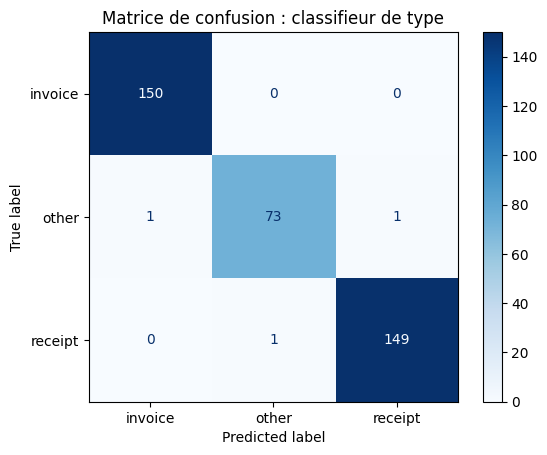

Latence : 75 ms par image (Colab)


In [2]:
import os, glob, shutil, time
import numpy as np, tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay


# copie locale des données (beaucoup plus rapide que lire sur Drive)
if not os.path.exists("/content/data"):
    shutil.copytree(f"{ROOT}/invoice_project_data", "/content/data")

TYPE_MODEL = "/content/drive/MyDrive/invoice_classifier.keras"
print("modèle :", TYPE_MODEL)

model = tf.keras.models.load_model(TYPE_MODEL)
test = tf.keras.utils.image_dataset_from_directory(
    "/content/data/test", image_size=(224, 224), batch_size=32, shuffle=False)
names = test.class_names                     # attendu : ['invoice', 'other', 'receipt']

y_true = np.concatenate([y.numpy() for _, y in test])
y_pred = np.argmax(model.predict(test), axis=1)

print(classification_report(y_true, y_pred, target_names=names, digits=3))

cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=names).plot(cmap="Blues", values_format="d")
plt.title("Matrice de confusion : classifieur de type")
plt.savefig(f"{ROOT}/cm_type.png", dpi=200, bbox_inches="tight")
plt.show()

# latence : une image à la fois (comme dans l'API)
x = np.zeros((1, 224, 224, 3), "float32")
model.predict(x, verbose=0)                  # préchauffage
t0 = time.time()
for _ in range(50):
    model.predict(x, verbose=0)
print(f"Latence : {(time.time() - t0) / 50 * 1000:.0f} ms par image (Colab)")

## 3. Jeu de données de qualité (good / poor)

### 3.1 Génération des images dégradées (flou, rotation, bruit, basse résolution)

In [ ]:
import cv2, glob, os, random
import numpy as np
random.seed(42)

def degrade(img):
    kind = random.choice(["blur", "rotate", "noise", "lowres"])
    h, w = img.shape[:2]
    if kind == "blur":
        k = random.choice([9, 15, 21])
        return cv2.GaussianBlur(img, (k, k), 0)
    if kind == "rotate":
        a = random.choice([-1, 1]) * random.uniform(12, 30)
        M = cv2.getRotationMatrix2D((w/2, h/2), a, 1.0)
        return cv2.warpAffine(img, M, (w, h), borderValue=(255, 255, 255))
    if kind == "noise":
        noise = np.random.normal(0, 40, img.shape)
        return np.clip(img + noise, 0, 255).astype(np.uint8)
    # lowres
    small = cv2.resize(img, (w // 6, h // 6))
    return cv2.resize(small, (w, h))

for split in ["train", "val", "test"]:
    files = glob.glob(f"/content/data/{split}/invoice/*") + glob.glob(f"/content/data/{split}/receipt/*")
    random.shuffle(files)
    for lab in ["good", "poor"]:
        os.makedirs(f"/content/quality/{split}/{lab}", exist_ok=True)
    for i, f in enumerate(files):
        img = cv2.imread(f)
        if img is None:
            continue
        if i % 2 == 0:
            cv2.imwrite(f"/content/quality/{split}/good/{i}.png", img)
        else:
            cv2.imwrite(f"/content/quality/{split}/poor/{i}.png", degrade(img))

!for d in /content/quality/*/*; do echo "$d: $(ls $d | wc -l)"; done

/content/quality/test/good: 150
/content/quality/test/poor: 150
/content/quality/train/good: 700
/content/quality/train/poor: 700
/content/quality/val/good: 150
/content/quality/val/poor: 150


### 3.2 Sauvegarde et restauration sur Drive

In [ ]:
!cp -r /content/quality /content/drive/MyDrive/invoice_project_quality

In [ ]:
!cp -r /content/drive/MyDrive/invoice_project_quality /content/quality

## 4. Classifieur de qualité (good / poor)

### 4.1 Entraînement, évaluation et sauvegarde

In [ ]:
import tensorflow as tf, numpy as np
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix

IMG, BATCH = (224, 224), 32
d = "/content/quality"
train = tf.keras.utils.image_dataset_from_directory(f"{d}/train", image_size=IMG, batch_size=BATCH)
val   = tf.keras.utils.image_dataset_from_directory(f"{d}/val",   image_size=IMG, batch_size=BATCH)
test  = tf.keras.utils.image_dataset_from_directory(f"{d}/test",  image_size=IMG, batch_size=BATCH, shuffle=False)
print(train.class_names)  # ['good', 'poor']

base = tf.keras.applications.MobileNetV2(input_shape=IMG + (3,), include_top=False, weights="imagenet")
base.trainable = False

model = models.Sequential([
    layers.Rescaling(1./127.5, offset=-1),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(2, activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

model.fit(train, validation_data=val, epochs=10,
          callbacks=[tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)])

print(model.evaluate(test))

y_true = np.concatenate([y.numpy() for _, y in test])
y_pred = np.argmax(model.predict(test), axis=1)
print(classification_report(y_true, y_pred, target_names=test.class_names))
print(confusion_matrix(y_true, y_pred))

model.save("/content/drive/MyDrive/quality_classifier.keras")

Found 1400 files belonging to 2 classes.
Found 300 files belonging to 2 classes.
Found 300 files belonging to 2 classes.
['good', 'poor']
Epoch 1/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 61s 1s/step - accuracy: 0.6957 - loss: 0.5952 - val_accuracy: 0.8700 - val_loss: 0.3280
Epoch 2/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 61s 823ms/step - accuracy: 0.9107 - loss: 0.2549 - val_accuracy: 0.8967 - val_loss: 0.2415
Epoch 3/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 43s 874ms/step - accuracy: 0.9321 - loss: 0.1935 - val_accuracy: 0.9200 - val_loss: 0.2191
Epoch 4/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 37s 795ms/step - accuracy: 0.9357 - loss: 0.1742 - val_accuracy: 0.9200 - val_loss: 0.1912
Epoch 5/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 38s 862ms/step - accuracy: 0.9450 - loss: 0.1544 - val_accuracy: 0.9300 - val_loss: 0.1907
Epoch 6/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 35s 793ms/step - accuracy: 0.9529 - loss: 0.1361 - val_accuracy: 0.9267 - val_loss: 0.1778
Epoch 7/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 40s 783ms/step - accuracy: 0.9521 - loss: 0.1270 - va

### 4.2 Courbe ROC et AUC

Mounted at /content/drive
modèle : /content/drive/MyDrive/quality_classifier.keras 
test   : /content/drive/MyDrive/invoice_project_quality/test
Found 300 files belonging to 2 classes.
['good', 'poor']
10/10 ━━━━━━━━━━━━━━━━━━━━ 43s 2s/step
AUC = 0.9953


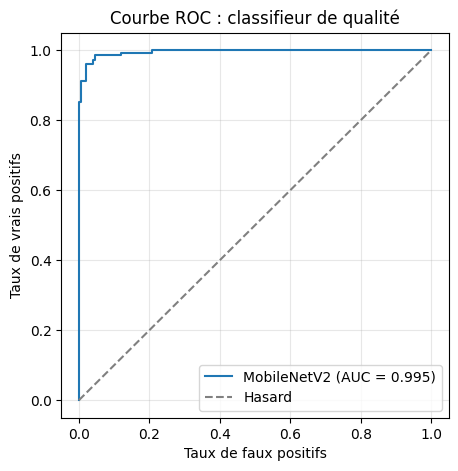

In [1]:
import os, numpy as np, tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

MODEL = "/content/drive/MyDrive/quality_classifier.keras"
TEST_DIR = next(p for p in [
    "/content/quality/test",
    "/content/drive/MyDrive/invoice_project_quality/test",
] if os.path.exists(p))
print("modèle :", MODEL, "\ntest   :", TEST_DIR)

# --- données et modèle ---
model = tf.keras.models.load_model(MODEL)
test = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, image_size=(224, 224), batch_size=32, shuffle=False)
print(test.class_names)          # attendu : ['good', 'poor']

y_true = np.concatenate([y.numpy() for _, y in test])
y_score = model.predict(test)[:, 1]      # probabilité de la classe 'poor'

# --- ROC et AUC ---
fpr, tpr, thr = roc_curve(y_true, y_score)
auc = roc_auc_score(y_true, y_score)
print(f"AUC = {auc:.4f}")

plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"MobileNetV2 (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Hasard")
plt.xlabel("Taux de faux positifs")
plt.ylabel("Taux de vrais positifs")
plt.title("Courbe ROC : classifieur de qualité")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("/content/drive/MyDrive/DL_Project/roc_quality.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. OCR et extraction des champs

### 5.1 Installation de Tesseract (français + anglais)

In [ ]:
# Installation (Tesseract + français/anglais)
!apt-get -qq install tesseract-ocr tesseract-ocr-fra
!pip -q install pytesseract

Selecting previously unselected package tesseract-ocr-fra.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-fra_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-fra (1:4.1.0-2) ...
Setting up tesseract-ocr-fra (1:4.1.0-2) ...


### 5.2 Règles d'extraction (fournisseur, date, total) et vérité terrain FATURA

In [ ]:
import os, json, glob, random, re, difflib
import pytesseract
from PIL import Image

# ---------- OCR + règles d'extraction ----------
def ocr(path):
    return pytesseract.image_to_string(Image.open(path).convert("L"), lang="fra+eng")

MONTH = r"(?:Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)[a-z]*"
DATE_PATTERNS = [
    rf"\b\d{{1,2}}[-/ .]{MONTH}[-/ .,]*\d{{2,4}}\b",
    rf"\b{MONTH}[ .]\d{{1,2}},? \d{{4}}\b",
    r"\b\d{4}[/\-.]\d{1,2}[/\-.]\d{1,2}\b",
    r"\b\d{1,2}[/\-.]\d{1,2}[/\-.]\d{2,4}\b",
]

def find_date(text):
    for line in text.splitlines():
        if re.search(r"date", line, re.I) and not re.match(r"\s*due", line, re.I):
            for p in DATE_PATTERNS:
                m = re.search(p, line, re.I)
                if m:
                    return m.group(0)
    return None

def find_supplier(text):
    for line in text.splitlines():
        l = re.sub(r"(commercial|tax)?\s*invoice", "", line, flags=re.I).strip()
        if len(re.findall(r"[A-Za-z]", l)) < 3: continue
        if re.match(r"\W*A\w{1,3}ress", l, re.I): continue
        if re.match(r"\d", l): continue
        if re.search(r",\s*[A-Z]{2}\s*\d{4,5}", l): continue
        if re.search(r"description|unit price|quantity|amount", l, re.I): continue
        if re.search(r"\bid\b|inv/|date|bill|#", l, re.I): continue
        name = re.split(r"\s*\W?\s*A\w{1,3}ress", l, flags=re.I)[0].strip()
        if len(name) >= 3:
            return name
    return None

def find_total(text):
    for line in reversed(text.splitlines()):
        if re.search(r"total|montant|amount|ttc", line, re.I):
            nums = re.findall(r"\d+[.,]\d{2}", line)
            if nums:
                return float(nums[-1].replace(",", "."))
    return None

def extract(text):
    return {"supplier": find_supplier(text), "date": find_date(text), "total": find_total(text)}

# ---------- Vérité terrain (annotations FATURA) ----------
imgs = {}
for p in glob.glob("/content/fatura/**/*.jpg", recursive=True):
    imgs.setdefault(os.path.basename(p), p)
js = glob.glob("/content/fatura/**/layoutlm_HF_format/*.json", recursive=True)

def truth(j):
    d = json.load(open(j))
    pick = lambda tag: [w for w, t in zip(d["words"], d["ner_tags"]) if t == tag]
    nums = [float(re.sub(r"[^\d.]", "", w)) for w in pick(1) if re.search(r"\d", w)]
    return d["path"], {
        "supplier": " ".join(pick(6)),
        "date": next((w for w in pick(3) if re.search(r"\d", w)), None),
        "total": nums[-1] if nums else None,
    }

random.seed(1)
N = 100         # mets 50 si tu manques de temps (~3 s par image)
sample = random.sample(js, N)
print("vérification :", truth(sample[0]))

# ---------- Normalisation (utilisée par l'évaluation) ----------
norm = lambda s: re.sub(r"[^a-z0-9]", "", str(s).lower())


vérification : ('Template13_Instance122.jpg', {'supplier': 'Fernandez PLC', 'date': '10-Dec-1996', 'total': 671.43})


### 5.3 Évaluation sur 100 factures (images où le champ est annoté)

In [ ]:
ok = {"supplier_exact": 0, "supplier_proche": 0, "date": 0, "total": 0}
cnt = {"supplier": 0, "date": 0, "total": 0}

for j in sample:
    name, gt = truth(j)
    if name not in imgs:
        continue
    pred = extract(ocr(imgs[name]))
    if gt["total"] is not None:
        cnt["total"] += 1
        if pred["total"] is not None and abs(pred["total"] - gt["total"]) < 0.01:
            ok["total"] += 1
    if gt["date"]:
        cnt["date"] += 1
        if pred["date"] and norm(pred["date"]) == norm(gt["date"]):
            ok["date"] += 1
    if gt["supplier"]:
        cnt["supplier"] += 1
        if pred["supplier"]:
            r = difflib.SequenceMatcher(None, norm(pred["supplier"]), norm(gt["supplier"])).ratio()
            ok["supplier_exact"] += (r == 1)
            ok["supplier_proche"] += (r >= 0.8)

print("images avec annotation :", cnt)
print({k: round(100 * ok[k] / cnt[k.split("_")[0]], 1) for k in ok})

images avec annotation : {'supplier': 71, 'date': 100, 'total': 85}
{'supplier_exact': 66.2, 'supplier_proche': 78.9, 'date': 93.0, 'total': 80.0}


## 6. Courbes d'entraînement
Réentraîne les deux modèles pour obtenir les courbes loss et accuracy (train et val).
Les nouveaux modèles sont sauvegardés sous le suffixe `_retrain` : les modèles utilisés par le service ne sont pas modifiés.

Found 1750 files belonging to 3 classes.
Found 375 files belonging to 3 classes.
Found 375 files belonging to 3 classes.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 83s 1s/step - accuracy: 0.8897 - loss: 0.2952 - val_accuracy: 0.9893 - val_loss: 0.0603
Epoch 2/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 44s 816ms/step - accuracy: 0.9811 - loss: 0.0633 - val_accuracy: 0.9920 - val_loss: 0.0358
Epoch 3/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 45s 808ms/step - accuracy: 0.9880 - loss: 0.0419 - val_accuracy: 0.9947 - val_loss: 0.0238
Epoch 4/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 43s 782ms/step - accuracy: 0.9914 - loss: 0.0313 - val_accuracy: 1.0000 - val_loss: 0.0172
Epoch 5/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 40s 719ms/step - accuracy: 0.9949 - loss: 0.0224 - val_accuracy: 1.0000 - val_loss: 0.0130
Epoch 6/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 42s 770ms/step - accuracy: 0.9954 - loss: 0.0202 - val_accuracy: 1.0000 - val_loss: 0.0102
Epoch 7/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 40s 732ms/step - accu

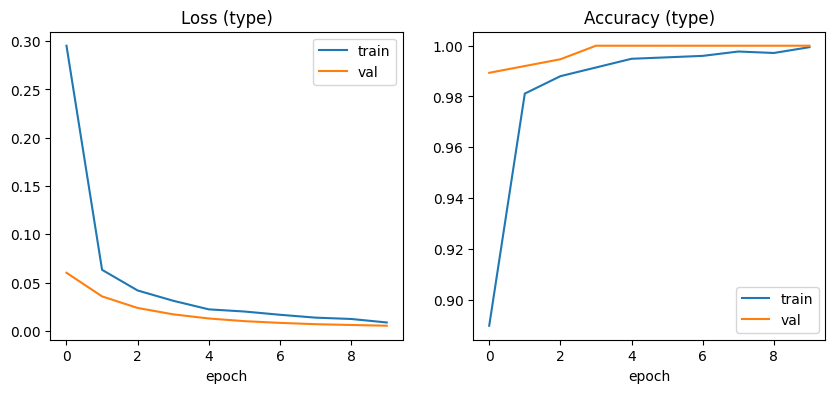

Found 1400 files belonging to 2 classes.
Found 300 files belonging to 2 classes.
Found 300 files belonging to 2 classes.
Epoch 1/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 72s 1s/step - accuracy: 0.8036 - loss: 0.4185 - val_accuracy: 0.8867 - val_loss: 0.3137
Epoch 2/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 42s 965ms/step - accuracy: 0.9114 - loss: 0.2358 - val_accuracy: 0.8933 - val_loss: 0.2141
Epoch 3/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 36s 830ms/step - accuracy: 0.9329 - loss: 0.1767 - val_accuracy: 0.9133 - val_loss: 0.1914
Epoch 4/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 44s 890ms/step - accuracy: 0.9457 - loss: 0.1499 - val_accuracy: 0.9233 - val_loss: 0.1780
Epoch 5/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 39s 886ms/step - accuracy: 0.9514 - loss: 0.1379 - val_accuracy: 0.9300 - val_loss: 0.1690
Epoch 6/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 40s 871ms/step - accuracy: 0.9564 - loss: 0.1224 - val_accuracy: 0.9400 - val_loss: 0.1814
Epoch 7/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 40s 854ms/step - accuracy: 0.9593 - loss: 0.1186 - val_accuracy: 0.933

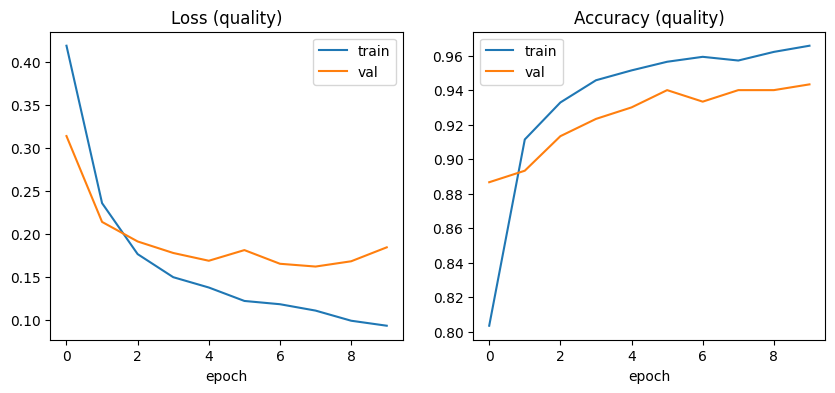

In [3]:
from tensorflow.keras import layers, models

def train_and_plot(data_dir, n_classes, name):
    train = tf.keras.utils.image_dataset_from_directory(
        f"{data_dir}/train", image_size=(224, 224), batch_size=32)
    val = tf.keras.utils.image_dataset_from_directory(
        f"{data_dir}/val", image_size=(224, 224), batch_size=32)
    test = tf.keras.utils.image_dataset_from_directory(
        f"{data_dir}/test", image_size=(224, 224), batch_size=32, shuffle=False)

    base = tf.keras.applications.MobileNetV2(
        input_shape=(224, 224, 3), include_top=False, weights="imagenet")
    base.trainable = False
    m = models.Sequential([
        layers.Rescaling(1./127.5, offset=-1), base,
        layers.GlobalAveragePooling2D(), layers.Dropout(0.2),
        layers.Dense(n_classes, activation="softmax")])
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

    h = m.fit(train, validation_data=val, epochs=10,
              callbacks=[tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)])
    print(f"{name} : test (loss, accuracy) =", m.evaluate(test))

    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].plot(h.history["loss"], label="train"); ax[0].plot(h.history["val_loss"], label="val")
    ax[0].set_title(f"Loss ({name})"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(h.history["accuracy"], label="train"); ax[1].plot(h.history["val_accuracy"], label="val")
    ax[1].set_title(f"Accuracy ({name})"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.savefig(f"{ROOT}/curves_{name}.png", dpi=200, bbox_inches="tight")
    plt.show()
    m.save(f"{ROOT}/{name}_classifier_retrain.keras")

# 1) type de document
train_and_plot("/content/data", 3, "type")

# 2) qualité (copie locale d'abord)
if not os.path.exists("/content/quality"):
    shutil.copytree(f"{ROOT}/invoice_project_quality", "/content/quality")
train_and_plot("/content/quality", 2, "quality")